Prepare Environment

In [35]:
from numpy import array, average, concatenate, cov, sqrt, trace
from pandas import read_csv
from seaborn import lineplot, scatterplot

In [36]:
# Find the ROOT & DATA path
from pathlib import Path
import sys

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists())
DATA_DIR = ROOT / "data"
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))  # lets 'from arpym...' work from any subfolder

Load Data
- From db_stocks_sp database , we upload the time series of the prices of AMZN and EOG stocks.

In [37]:
db_stocks_sp = read_csv(DATA_DIR /"db_stocks_sp.csv", index_col=0, header=1, usecols=['date', 'AMZN', 'EOG'])

- From SPX database, we upload the time series of the stocks in the S&P 500 index and filter the
matching stock index.

In [38]:
db_stocks_sp500_spx = read_csv(DATA_DIR/"SPX.csv", parse_dates=True, index_col=0, date_format='mixed')

# filter S&P 500 matching stock index
v_spx = db_stocks_sp500_spx[(db_stocks_sp500_spx.index >= db_stocks_sp.index[0])&
                            (db_stocks_sp500_spx.index <= db_stocks_sp.index[-1])].values

Task 1a: returns and stacking
- Compute the realizations of the respective daily linear returns.

In [39]:
# Target: stock returns

# price today / price yesterday - 1
# [1:] is today
# [:-1] - 1 is yesterday shifted by 1 row

# Daily returns of AMZN (col 0) and EOG (col 1)
x = db_stocks_sp.values[1:, :]/db_stocks_sp.values[:-1, :] - 1
print("X shape = ", x.shape)
print()

# factor: Daily S&P 500 returns
z = v_spx[1:]/v_spx[:-1] - 1
print("Z shape = ", z.shape)
print()

# concatenate target and factor -> (all 3 side by side)
xz = concatenate((x, z), axis=1)
print("XZ shape = ", xz.shape)

X shape =  (1599, 2)

Z shape =  (1599, 1)

XZ shape =  (1599, 3)


Task 1b: sample moments
- Estimate the first 2 moments of the joint distribution of (X1, X2, Z)' by using the sample mean and covariance.

In [40]:
# sample mean
e_xz = average(xz, axis=0)

# sample covariance
cv_xz = cov(xz.T)

############# results ##############
print('e_xz = ', e_xz.round(6))
print()
print('cv_xz \n', cv_xz.round(6))

e_xz =  [0.001825 0.000711 0.000178]

cv_xz 
 [[0.000864 0.000289 0.000257]
 [0.000289 0.000788 0.000296]
 [0.000257 0.000296 0.000233]]


Task 2a: β and α
- Consider the sample mean and covariance computed in Task 1
- Compute the regression loadings β = (β1,β2)' and the regression shift parameters α (α1,α2)'.

In [41]:
############### input ################

# number of stocks
n_bar = x.shape[1]
print('n_bar = ', n_bar)
print()

######################################

# regression loadings
# with n_bar = 2 then -> cv_xz[:n_bar, n_bar:] is rows 0-1, column 2
# which is Cov(stocks,SPX, shape(2,1)
# cv_xz[n_bar, n_bar] -> cv_xz[2, 2] -> which is Var(SPX)
# (2,1) column holding both betas
beta = cv_xz[:n_bar, n_bar:]/cv_xz[n_bar, n_bar]
print('Beta shape = ', beta.shape)
print()

# regression shift
# e_xz[:n_bar] -> e_xz[:2] the SPX mean
# so beta @ e_xz[2:] gives B.E{Z} for each stock, and alpha has shape (2,)
alpha = e_xz[:n_bar] - beta@e_xz[n_bar:]
print('alpha shape = ', alpha.shape)
print()

############ results ############
print('beta \n', beta.round(4))
print()
print('alpha =', alpha.round(4))

n_bar =  2

Beta shape =  (2, 1)

alpha shape =  (2,)

beta 
 [[1.1054]
 [1.2708]]

alpha = [0.0016 0.0005]


Task 2b: R2
- Compute the maximal r_squared(with scale sigma2 = I2) achieved by the regression model.

In [43]:
# r-squared
# beta @ Var(Z) @ beta.T is the 2×2 covariance of the explained part of the returns
# cv_xz[:2, :2] is Cov(stocks), and its trace is the total variance.
r2 = trace(beta@cv_xz[n_bar:, n_bar:]@beta.T)/trace(cv_xz[:n_bar, :n_bar])
print('r2 = ', r2.round(2))
print()
print(f"The market explains {r2.round(2)*100}% of the 2 stocks combined daily variance")

r2 =  0.4

The market explains 40.0% of the 2 stocks combined daily variance


Task 3: Residuals
- Verify that the residuals (E1, E2)' of the regression model are uncorrelated with the factor Z,
but NOT uncorrelated among each other.

In [44]:
# Realized residuals
eps = x - alpha - z@beta.T
print('Realized residuals shape = ', eps.shape)
print()

# Factor and Residual cross-covariance: verify that entries are null
# Cov(SPX, E1) and Cov(SPX, E2): row 0 (SPX) against columns 1-2(the residuals)
# of the joint covariance
cv_z_eps = cov(concatenate((z, eps), axis=1).T)[0, 1:]
print('Factor and Residuals Cross-Covariance = ', cv_z_eps.shape)
print()

# Residuals covariance: verify that it is NOT diagonal
# 2x2 residual covariance
cv_eps = cov(eps.T)
print('Residuals covariance shape = ', cv_eps.shape)
print()

############## Results ##############
print('cv_z_eps \n', cv_z_eps.round(4))
print()
print('cv_eps \n', cv_eps.round(6))

Realized residuals shape =  (1599, 2)

Factor and Residuals Cross-Covariance =  (2,)

Residuals covariance shape =  (2, 2)

cv_z_eps 
 [0. 0.]

cv_eps 
 [[ 5.79e-04 -3.80e-05]
 [-3.80e-05  4.12e-04]]


**Note**: Residuals are uncorrelated with $Z$ by construction of the regression loadings, but $\mathrm{Cov}\{\varepsilon_1,\varepsilon_2\}\neq 0$: AMZN and EOG share drivers beyond the S&P 500. Treating residuals as independent (diagonal covariance) would therefore misstate portfolio idiosyncratic risk.

Task 4: portfolio β̃ and α̃
- Consider a portfolio with weights w=(0.3, 0.7)' in the 2 stocks, and the following regression
model on the linear return of the portfolio Y = w'X

In [45]:
#################### input ####################

# portfolio weights
w = array([[0.3, 0.7]]).T
print('Weights w shape = ', w.shape)
print()

###############################################

# regression loadings
beta_tilde = w.T@beta
print('beta tilda shape = ', beta_tilde.shape)
print()

# regression shift
alpha_tilde = w.T@alpha
print('alpha tilda shape = ', alpha_tilde.shape)
print()

################## results ##################
print('beta_tilde =', beta_tilde.round(4))
print()
print('alpha_tilde =', alpha_tilde.round(4))

Weights w shape =  (2, 1)

beta tilda shape =  (1, 1)

alpha tilda shape =  (1,)

beta_tilde = [[1.2212]]

alpha_tilde = [0.0008]


Task 5: plot

- Display the scatter plot of the joint historical scenarios of the S&P 500 index return and
portfolio return (Z,Y)' and overlay in the same figure the regression line from Task 4 above.

y shape =  (1599, 1)



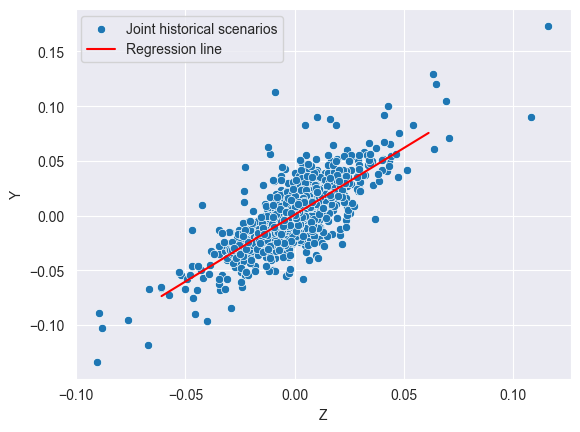

In [47]:
# target: linear return of portfolio
# each days portfolio return is 0.3*AMZN + 0.7*EOG
y = x @ w
print('y shape = ', y.shape)
print()

# grid of points for factor
# 4std deviation - giving 2 endpoints of the line
z_grid = array([e_xz[2] - 4*sqrt(cv_xz[2, 2]), e_xz[2] + 4*sqrt(cv_xz[2, 2])])

# the portfolio's regression line, evaluated at those endpoints
y_reg = alpha_tilde + beta_tilde * z_grid

################################################ plot ################################################
# scatterplot and regression line
scatterplot(x=z.flatten(), y=y.flatten(), label='Joint historical scenarios')
lineplot(x=z_grid, y=y_reg.flatten(), color='r', label='Regression line').set(xlabel='Z', ylabel='Y');

# I see a cloud of daily (market, portfolio) returns tilted upwards, being at its most densest at 0,0,
# with a red line running through at slope beta